### 랭그래프란?
- 대규모 언어 모델(LLM)을 기반으로 여러 단계에 걸쳐 작동하는 정교한 AI 에이전트와 워크플로우를 구축하기 위한 오픈소스 프레임워크.

#### 💡 핵심 특징 3가지
- 순환 구조와 루프(Cycles & Loops)
    - 작업 결과가 만족스러울 때까지 피드백을 받아 반복하거나 사용자 입력을 다시 받아오는 것처럼 단방향 체인으로는 구현하기 힘든 비선형적 흐름을 자유롭게 설계할 수 있습니다.

- 상태 유지(Stateful)
    - 여러 단계나 다중 에이전트 간에 데이터를 공유하고 축적하는 중앙 '상태(State)' 관리 기능이 있어, 과거의 대화나 작업 맥락을 끊김 없이 이어갑니다.

- 멀티 에이전트 시스템(Multi-Agent Systems)
    - 리더, 프로그래머, 테스터처럼 역할을 나눈 여러 AI 에이전트들이 노드로서 서로 협업하고 데이터를 주고받는 고도화된 시스템을 구축하기에 최적화되어 있습니다.

#### 🧪 실습
- 랭그래프 공식 문서 참고
    -  https://docs.langchain.com/oss/python/langgraph/overview

In [ ]:
# 랭그래프 설치
% uv add langgraph

In [3]:
from dotenv import load_dotenv
import os

load_dotenv()
api_key = os.getenv('OPENAI_API_KEY')

In [4]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-5.6-luna")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXRBHNbKxeMqphyXY7UFnFvENu3Gu', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a125f2-86b3-7f52-b8dc-013cc1347d5e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

##### State 클래스 정의
- 랭그래프에서는 각 작업을 진행하는데 필요한 항목들의 자료 형태를 상태에 미리 정해 놓아야, 각 노드가 필요한 정보를 정확히 받아 작업이 순차로 잘 이어진다. 

In [5]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):	
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다.  
       'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다. 
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) 

##### 노드 생성
- 그래프의 한 지점, 하나의 단계를 표현한다. 
- 랭그래프는 각 노드에서 처리한 결과를 상태에서 관리한다. 
- 각 노드를 엣지로 연결하는 그래프 형태로 표현하여 대화나 데이터 흐름을 관리한다. 

In [6]:
def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.
		
    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """ 
    return {"messages": [model.invoke(state["messages"])]}

graph_builder.add_node("generate", generate) # 인자 : 노드의 이름과 해당 함수명

##### 엣지 설정
- 노드 앞 뒤로 START, END 노드(랭그래프에서 제공하는 노드)를 지정하고 엣지 설정.

In [7]:
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)    

graph = graph_builder.compile()

- 우리가 만든 그래프의 구조를 파이썬으로 시각화해보자.

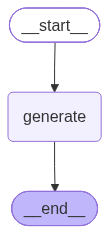

In [8]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception: 
    pass

- 리스트에 문장을 추가해 그래프를 이용해 답변 생성.

In [17]:
from rich.pretty import pprint

response = graph.invoke({"messages": ["안녕하세요! 저는 김솔입니다"]})

print(type(response))
pprint(response)

<class 'dict'>


{
│   'messages': [
│   │   HumanMessage(
│   │   │   content='안녕하세요! 저는 김솔입니다',
│   │   │   additional_kwargs={},
│   │   │   response_metadata={},
│   │   │   id='dc0b801e-54e1-477b-b7fd-aee4a409c0c8'
│   │   ),
│   │   AIMessage(
│   │   │   content='안녕하세요, 김솔님! 만나서 반갑습니다. 무엇을 도와드릴까요?',
│   │   │   additional_kwargs={'refusal': None},
│   │   │   response_metadata={
│   │   │   │   'token_usage': {
│   │   │   │   │   'completion_tokens': 24,
│   │   │   │   │   'prompt_tokens': 13,
│   │   │   │   │   'total_tokens': 37,
│   │   │   │   │   'completion_tokens_details': {
│   │   │   │   │   │   'accepted_prediction_tokens': 0,
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'reasoning_tokens': 0,
│   │   │   │   │   │   'rejected_prediction_tokens': 0,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   },
│   │   │   │   │   'prompt_tokens_details': {
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'cache_write_tokens': 0,
│   │   │   │   │   │   'cached_tokens': 0,
│   │   │   │   │   │   'image_tokens': None,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   'model_provider': 'openai',
│   │   │   │   'model_name': 'gpt-5.6-luna',
│   │   │   │   'system_fingerprint': None,
│   │   │   │   'id': 'chatcmpl-EXRXyOpGxDR4G2E8abMN8wSuCN1XI',
│   │   │   │   'service_tier': 'default',
│   │   │   │   'finish_reason': 'stop',
│   │   │   │   'logprobs': None
│   │   │   },
│   │   │   id='lc_run--01a12608-0339-7551-9d7b-ece2bee5eb37-0',
│   │   │   tool_calls=[],
│   │   │   invalid_tool_calls=[],
│   │   │   usage_metadata={
│   │   │   │   'input_tokens': 13,
│   │   │   │   'output_tokens': 24,
│   │   │   │   'total_tokens': 37,
│   │   │   │   'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0},
│   │   │   │   'output_token_details': {'audio': 0, 'reasoning': 0}
│   │   │   }
│   │   )
│   ]
}

In [18]:
response["messages"].append("제 이름을 기억하시나요?")
pprint(graph.invoke(response))

{
│   'messages': [
│   │   HumanMessage(
│   │   │   content='안녕하세요! 저는 김솔입니다',
│   │   │   additional_kwargs={},
│   │   │   response_metadata={},
│   │   │   id='dc0b801e-54e1-477b-b7fd-aee4a409c0c8'
│   │   ),
│   │   AIMessage(
│   │   │   content='안녕하세요, 김솔님! 만나서 반갑습니다. 무엇을 도와드릴까요?',
│   │   │   additional_kwargs={'refusal': None},
│   │   │   response_metadata={
│   │   │   │   'token_usage': {
│   │   │   │   │   'completion_tokens': 24,
│   │   │   │   │   'prompt_tokens': 13,
│   │   │   │   │   'total_tokens': 37,
│   │   │   │   │   'completion_tokens_details': {
│   │   │   │   │   │   'accepted_prediction_tokens': 0,
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'reasoning_tokens': 0,
│   │   │   │   │   │   'rejected_prediction_tokens': 0,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   },
│   │   │   │   │   'prompt_tokens_details': {
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'cache_write_tokens': 0,
│   │   │   │   │   │   'cached_tokens': 0,
│   │   │   │   │   │   'image_tokens': None,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   'model_provider': 'openai',
│   │   │   │   'model_name': 'gpt-5.6-luna',
│   │   │   │   'system_fingerprint': None,
│   │   │   │   'id': 'chatcmpl-EXRXyOpGxDR4G2E8abMN8wSuCN1XI',
│   │   │   │   'service_tier': 'default',
│   │   │   │   'finish_reason': 'stop',
│   │   │   │   'logprobs': None
│   │   │   },
│   │   │   id='lc_run--01a12608-0339-7551-9d7b-ece2bee5eb37-0',
│   │   │   tool_calls=[],
│   │   │   invalid_tool_calls=[],
│   │   │   usage_metadata={
│   │   │   │   'input_tokens': 13,
│   │   │   │   'output_tokens': 24,
│   │   │   │   'total_tokens': 37,
│   │   │   │   'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0},
│   │   │   │   'output_token_details': {'audio': 0, 'reasoning': 0}
│   │   │   }
│   │   ),
│   │   HumanMessage(
│   │   │   content='제 이름을 기억하시나요?',
│   │   │   additional_kwargs={},
│   │   │   response_metadata={},
│   │   │   id='de66ea76-d976-42db-a0c4-f2ab95ac4439'
│   │   ),
│   │   AIMessage(
│   │   │   content='네, 기억하고 있어요. 이름이 **김솔**님이시죠!',
│   │   │   additional_kwargs={'refusal': None},
│   │   │   response_metadata={
│   │   │   │   'token_usage': {
│   │   │   │   │   'completion_tokens': 21,
│   │   │   │   │   'prompt_tokens': 51,
│   │   │   │   │   'total_tokens': 72,
│   │   │   │   │   'completion_tokens_details': {
│   │   │   │   │   │   'accepted_prediction_tokens': 0,
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'reasoning_tokens': 0,
│   │   │   │   │   │   'rejected_prediction_tokens': 0,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   },
│   │   │   │   │   'prompt_tokens_details': {
│   │   │   │   │   │   'audio_tokens': 0,
│   │   │   │   │   │   'cache_write_tokens': 0,
│   │   │   │   │   │   'cached_tokens': 0,
│   │   │   │   │   │   'image_tokens': None,
│   │   │   │   │   │   'text_tokens': None
│   │   │   │   │   }
│   │   │   │   },
│   │   │   │   'model_provider': 'openai',
│   │   │   │   'model_name': 'gpt-5.6-luna',
│   │   │   │   'system_fingerprint': None,
│   │   │   │   'id': 'chatcmpl-EXRY1dKEvJ5UZ6FSBVxwWyJ25VA8P',
│   │   │   │   'service_tier': 'default',
│   │   │   │   'finish_reason': 'stop',
│   │   │   │   'logprobs': None
│   │   │   },
│   │   │   id='lc_run--01a12608-0cc7-7723-9379-1a3ef9e40e55-0',
│   │   │   tool_calls=[],
│   │   │   invalid_tool_calls=[],
│   │   │   usage_metadata={
│   │   │   │   'input_tokens': 51,
│   │   │   │   'output_tokens': 21,
│   │   │   │   'total_tokens': 72,
│   │   │   │   'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0},
│   │   │   │   'output_token_details': {'audio': 0, 'reasoning': 0}
│   │   │   }
│   │   )
│   ]
}

##### 스트림 방식으로 출력하기
- .invoke 대신 .stream 사용.
- stream_mode를 messages 로 선택.

In [20]:
inputs = {"messages": [("human", "랭체인과 랭그래프의 차이점은 무엇인가요?")]}
for chunk, _ in graph.stream(inputs, stream_mode="messages"):
    print(chunk.content, end="")

랭체인(LangChain)과 랭그래프(LangGraph)는 모두 LLM 애플리케이션 개발을 위한 도구이지만, **추상화 수준과 주요 목적**이 다릅니다.

## 한눈에 비교

| 구분 | LangChain | LangGraph |
|---|---|---|
| 핵심 목적 | LLM 기능을 쉽게 조합하고 애플리케이션을 빠르게 개발 | 복잡하고 상태가 있는 에이전트 워크플로를 정교하게 제어 |
| 구조 | 체인, 도구, 리트리버, 에이전트 등 고수준 추상화 | 노드와 엣지로 구성된 상태 기반 그래프 |
| 흐름 | 주로 순차적 또는 프레임워크가 관리하는 흐름 | 분기, 반복, 재시도, 순환 등 자유로운 흐름 |
| 상태 관리 | 상대적으로 단순 | 대화 상태와 실행 상태를 명시적으로 관리 |
| 적합한 경우 | RAG, 문서 질의, 간단한 챗봇, 기본 에이전트 | 장기 실행 에이전트, 멀티 에이전트, 승인 절차, 사람 개입 |
| 난이도 | 비교적 쉬움 | 더 많은 설계와 코드 필요 |

## LangChain이란?

LangChain은 LLM 애플리케이션을 만들 때 필요한 여러 구성 요소를 연결해 주는 프레임워크입니다.

예를 들어 다음과 같은 작업에 적합합니다.

- 프롬프트 템플릿 관리
- LLM 호출
- 문서 로딩 및 임베딩
- 벡터 데이터베이스 검색
- RAG 구현
- 외부 API나 도구 호출
- 간단한 에이전트 구축

예를 들어 다음과 같은 흐름을 만들 수 있습니다.

```text
사용자 질문
 → 관련 문서 검색
 → 검색 결과와 질문을 LLM에 전달
 → 답변 생성
```

즉, **일반적인 LLM 기능을 빠르게 조합하는 데 강점**이 있습니다.

## LangGraph란?

LangGraph는 LLM 애플리케이션의 실행 흐름을 **그래프 형태로 직접 설계**하는 프레임워크입니다.

각 단계는 노드(node)가 되고, 단계 간 이동은 엣지(edge)로 표현합니다.

```text
질문 분석
   ├─ 일반 질문 → 바로 답변
   └─ 복잡한 질문 

##### 다양한 스트림 모드
- 참고 : https://docs.langchain.com/oss/python/langgraph/streaming

| 모드 | 타입 | 설명 |
|---|---|---|
| `values` | `ValuesStreamPart` | 각 단계가 끝난 뒤의 **전체 그래프 상태**를 전달합니다. |
| `updates` | `UpdatesStreamPart` | 각 단계가 끝난 뒤 발생한 **상태 변경분**을 전달합니다. 같은 단계에서 여러 번 변경되면 각각 별도로 전달됩니다. |
| `messages` | `MessagesStreamPart` | LLM 호출에서 생성되는 **토큰과 메타데이터의 쌍**을 전달합니다. |
| `custom` | `CustomStreamPart` | 노드에서 `get_stream_writer()`를 통해 보낸 **사용자 정의 데이터**를 전달합니다. |
| `checkpoints` | `CheckpointStreamPart` | 체크포인트 이벤트를 전달합니다. 데이터 형식은 `get_state()`와 같습니다. **Checkpointer가 필요합니다.** |
| `tasks` | `TasksStreamPart` | 작업의 시작·완료 이벤트와 결과 또는 오류를 전달합니다. **Checkpointer가 필요합니다.** |
| `debug` | `DebugStreamPart` | 사용 가능한 상세 정보를 전달합니다. `checkpoints`와 `tasks` 내용에 추가 메타데이터가 포함됩니다. |
